In [1]:
from keras.datasets import imdb

vocab_size = 10_000

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
    num_words=vocab_size
)

print(f"{train_data.shape=}")
print(f"{train_labels.shape=}")
print(f"{test_data.shape=}")
print(f"{test_labels.shape=}")

train_data.shape=(25000,)
train_labels.shape=(25000,)
test_data.shape=(25000,)
test_labels.shape=(25000,)


In [2]:
word_index = imdb.get_word_index()
inverted_word_index = {value: key for key, value in word_index.items()}
decoded_seq = " ".join(
    [inverted_word_index.get(token - 3, "?") for token in train_data[0]]
)
decoded_seq[:100]

"? this film was just brilliant casting location scenery story direction everyone's really suited the"

In [3]:
import numpy as np


def one_hot_encode(sequences, vocab_size):
    x = np.zeros(shape=(len(sequences), vocab_size), dtype="float32")
    for i, sequence in enumerate(sequences):
        x[i, sequence] = 1.0
    return x

In [4]:
x_train = one_hot_encode(train_data, vocab_size)
x_test = one_hot_encode(test_data, vocab_size)
y_train = train_labels.astype("float32")
y_test = test_labels.astype("float32")

print(f"{x_train.shape=}")
print(f"{y_train.shape=}")
print(f"{x_test.shape=}")
print(f"{y_test.shape=}")

x_train.shape=(25000, 10000)
y_train.shape=(25000,)
x_test.shape=(25000, 10000)
y_test.shape=(25000,)


In [5]:
import keras

keras.utils.set_random_seed(1)

model = keras.Sequential(
    [
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ]
)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

num_epoch = 20
history = model.fit(
    x_train,
    y_train,
    batch_size=512,
    epochs=num_epoch,
    validation_split=0.2,
)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7725 - loss: 0.5344 - val_accuracy: 0.8528 - val_loss: 0.3849
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8992 - loss: 0.2891 - val_accuracy: 0.8898 - val_loss: 0.2874
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9290 - loss: 0.2082 - val_accuracy: 0.8966 - val_loss: 0.2751
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9450 - loss: 0.1670 - val_accuracy: 0.8866 - val_loss: 0.2963
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9535 - loss: 0.1419 - val_accuracy: 0.8896 - val_loss: 0.2961
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9590 - loss: 0.1210 - val_accuracy: 0.8836 - val_loss: 0.3223
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9653 - loss: 0.1059 - val_accuracy: 0.8760 - val_loss: 0.3533
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9707 - loss: 0.0934 - val_accuracy: 0.8848 - val_loss:

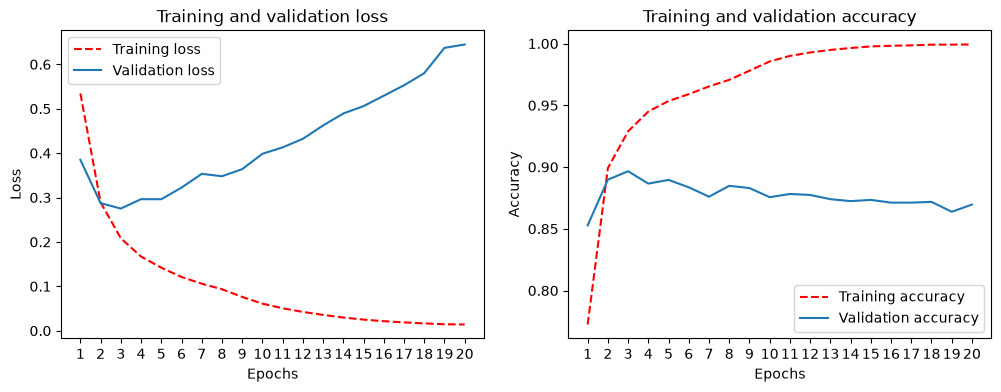

In [6]:
import matplotlib.pyplot as plt

epochs = range(1, num_epoch + 1)

loss_values = history.history["loss"]
val_loss_values = history.history["val_loss"]
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, loss_values, "r--", label="Training loss")
ax1.plot(epochs, val_loss_values, label="Validation loss")
ax1.set(
    title="Training and validation loss", xlabel="Epochs", ylabel="Loss", xticks=epochs
)
ax1.legend()

ax2.plot(epochs, accuracy, "r--", label="Training accuracy")
ax2.plot(epochs, val_accuracy, label="Validation accuracy")
ax2.set(
    title="Training and validation accuracy",
    xlabel="Epochs",
    ylabel="Accuracy",
    xticks=epochs,
)
ax2.legend()

plt.show()

In [7]:
results = model.evaluate(x_test, y_test)
loss, accuracy = results
print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 0s 295us/step - accuracy: 0.8545 - loss: 0.6795
Loss: 0.6795
Accuracy: 0.8545
